# Skin Cancer Classification - Tabular Data Analysis

## Import Libraries

In [1]:
# 1. Libraries
import os                  # Working with files and folders
import warnings            # Managing warning messages

# Data Manipulation
import pandas as pd
import numpy as np

# Data Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# 2. Check working directory

# Display the current working directory
print(os.getcwd())

C:\Users\97152\DMML


In [3]:
# 3. Display files and folders in the current directory
print(os.listdir())

['.ipynb_checkpoints', 'clinical_data.csv', 'EDA.ipynb', 'TabularDataAnalysis.ipynb']


In [4]:
# 4. Load the CSV file into a Pandas DataFrame
df = pd.read_csv(r"C:\Users\97152\OneDrive\Documents\Heriot Watt Uni\DMML\clinical_data.csv")

# Stage 1 - Data Inspection

In [5]:
# Display the first 5 rows
df.head()

,patient_id,lesion_id,smoke,drink,background_father,background_mother,age,pesticide,gender,skin_cancer_history,...,diameter_2,diagnostic,itch,grew,hurt,changed,bleed,elevation,img_id,biopsed
0,PAT_1516,1765,NaN,NaN,NaN,NaN,8,NaN,NaN,NaN,...,NaN,NEV,FALSE,FALSE,FALSE,FALSE,FALSE,FALSE,PAT_1516_1765_530.png,False
1,PAT_46,881,False,False,POMERANIA,POMERANIA,55,False,FEMALE,True,...,5.0,BCC,TRUE,TRUE,FALSE,TRUE,TRUE,TRUE,PAT_46_881_939.png,True
2,PAT_1545,1867,NaN,NaN,NaN,NaN,77,NaN,NaN,NaN,...,NaN,ACK,TRUE,FALSE,FALSE,FALSE,FALSE,FALSE,PAT_1545_1867_547.png,False
3,PAT_1989,4061,NaN,NaN,NaN,NaN,75,NaN,NaN,NaN,...,NaN,ACK,TRUE,FALSE,FALSE,FALSE,FALSE,FALSE,PAT_1989_4061_934.png,False
4,PAT_684,1302,False,True,POMERANIA,POMERANIA,79,False,MALE,True,...,5.0,BCC,TRUE,TRUE,FALSE,FALSE,TRUE,TRUE,PAT_684_1302_588.png,True


In [6]:
# 5. UNDERSTANDING THE DATASET
# Display the number of rows and columns
print(df.shape)

(2298, 26)


In [7]:
# Display all column names
print(df.columns)

Index(['patient_id', 'lesion_id', 'smoke', 'drink', 'background_father',
       'background_mother', 'age', 'pesticide', 'gender',
       'skin_cancer_history', 'cancer_history', 'has_piped_water',
       'has_sewage_system', 'fitspatrick', 'region', 'diameter_1',
       'diameter_2', 'diagnostic', 'itch', 'grew', 'hurt', 'changed', 'bleed',
       'elevation', 'img_id', 'biopsed'],
      dtype='object')


In [8]:
# Display information about the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2298 entries, 0 to 2297
Data columns (total 26 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   patient_id           2298 non-null   object 
 1   lesion_id            2298 non-null   int64  
 2   smoke                1494 non-null   object 
 3   drink                1494 non-null   object 
 4   background_father    1480 non-null   object 
 5   background_mother    1476 non-null   object 
 6   age                  2298 non-null   int64  
 7   pesticide            1494 non-null   object 
 8   gender               1494 non-null   object 
 9   skin_cancer_history  1494 non-null   object 
 10  cancer_history       1494 non-null   object 
 11  has_piped_water      1494 non-null   object 
 12  has_sewage_system    1494 non-null   object 
 13  fitspatrick          1494 non-null   float64
 14  region               2298 non-null   object 
 15  diameter_1           1494 non-null   f

In [9]:
# 6. Check missing values
# Count missing values in each column
print(df.isnull().sum())

patient_id               0
lesion_id                0
smoke                  804
drink                  804
background_father      818
background_mother      822
age                      0
pesticide              804
gender                 804
skin_cancer_history    804
cancer_history         804
has_piped_water        804
has_sewage_system      804
fitspatrick            804
region                   0
diameter_1             804
diameter_2             804
diagnostic               0
itch                     0
grew                     0
hurt                     0
changed                  0
bleed                    0
elevation                0
img_id                   0
biopsed                  0
dtype: int64


In [10]:
# Calculate missing values as a percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100

# Display the results
print(missing_percentage)

patient_id              0.000000
lesion_id               0.000000
smoke                  34.986945
drink                  34.986945
background_father      35.596171
background_mother      35.770235
age                     0.000000
pesticide              34.986945
gender                 34.986945
skin_cancer_history    34.986945
cancer_history         34.986945
has_piped_water        34.986945
has_sewage_system      34.986945
fitspatrick            34.986945
region                  0.000000
diameter_1             34.986945
diameter_2             34.986945
diagnostic              0.000000
itch                    0.000000
grew                    0.000000
hurt                    0.000000
changed                 0.000000
bleed                   0.000000
elevation               0.000000
img_id                  0.000000
biopsed                 0.000000
dtype: float64


In [11]:
# Display the number of unique values in each column
print(df.nunique())

patient_id             1373
lesion_id              1641
smoke                     2
drink                     2
background_father        13
background_mother        11
age                      84
pesticide                 2
gender                    2
skin_cancer_history       2
cancer_history            2
has_piped_water           2
has_sewage_system         2
fitspatrick               6
region                   14
diameter_1               42
diameter_2               38
diagnostic                6
itch                      3
grew                      3
hurt                      3
changed                   3
bleed                     3
elevation                 3
img_id                 2298
biopsed                   2
dtype: int64


#### CLASSIFICATION OF DATASET VARIABLES

#### Numerical Variables
##### age, diameter_1, diameter_2

#### Categorical Variables
##### gender, region, diagnostic
##### background_father, background_mother, fitspatrick

#### Identifiers
##### patient_id, lesion_id, img_id

In [12]:
# 7. Target Variable Distribution
# Count records in each diagnostic category
print(df["diagnostic"].value_counts())

diagnostic
BCC    845
ACK    730
NEV    244
SEK    235
SCC    192
MEL     52
Name: count, dtype: int64


In [13]:
# Calculate the percentage of each diagnostic category
print(df["diagnostic"].value_counts(normalize=True) * 100)

diagnostic
BCC    36.771105
ACK    31.766754
NEV    10.617929
SEK    10.226284
SCC     8.355091
MEL     2.262837
Name: proportion, dtype: float64


# Stage 2 - Exploratory Data Analysis - Univariate Analysis

### EDA - NUMERICAL VARIABLES

In [14]:
# 8. Generate descriptive statistics
df[["age", "diameter_1", "diameter_2"]].describe()

,age,diameter_1,diameter_2
count,2298.000000,1494.000000,1494.000000
mean,60.464752,11.897055,8.852209
std,15.894866,8.634492,5.797036
min,6.000000,0.000000,0.000000
25%,52.000000,7.000000,5.000000
50%,62.000000,10.000000,8.000000
75%,72.000000,15.000000,10.000000
max,94.000000,100.000000,70.000000


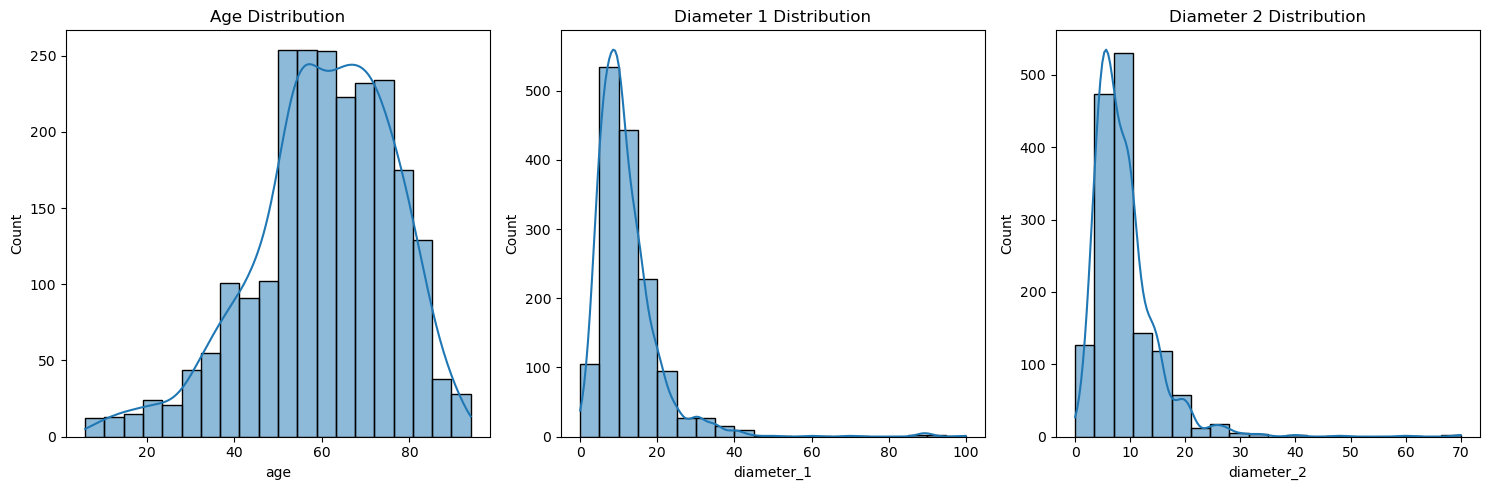

In [15]:
# 9. HISTOGRAMS - NUMERICAL VARIABLES
# Create three subplots
fig, axes = plt.subplots(1, 3, figsize=(15, 5)) #creates one row containing three plots.
# figsize changes the size of the figure

# bins=20 divides the data into 20 intervals
# kde=True adds a smooth curve showing the estimated distribution
# axes[0], axes[1], axes[2] refer to the first, second and third plots

# Age distribution
sns.histplot(data=df, x="age", bins=20, kde=True, ax=axes[0])
axes[0].set_title("Age Distribution")

# Diameter 1 distribution
sns.histplot(data=df, x="diameter_1", bins=20, kde=True, ax=axes[1])
axes[1].set_title("Diameter 1 Distribution")

# Diameter 2 distribution
sns.histplot(data=df, x="diameter_2", bins=20, kde=True, ax=axes[2])
axes[2].set_title("Diameter 2 Distribution")

# Adjust layout
plt.tight_layout()

# Display plots
plt.show()

### Observations – Numerical Variable Distributions

**Age**
- The age distribution is slightly left-skewed (negatively skewed).
- Most patients are concentrated in the older age groups.

**Diameter 1**
- The distribution is right-skewed (positively skewed).
- Most observations have smaller lesion measurements, with a few considerably larger values.

**Diameter 2**
- The distribution is right-skewed (positively skewed).
- Most observations have smaller lesion measurements, with a few considerably larger values.

### EDA - CATEGORICAL VARIABLES

In [16]:
# 10. EDA - CATEGORICAL VARIABLES
# Count records in each gender category
print(df["gender"].value_counts())

gender
FEMALE    753
MALE      741
Name: count, dtype: int64


In [17]:
# Calculate gender distribution as percentages
print(df["gender"].value_counts(normalize=True) * 100)

gender
FEMALE    50.401606
MALE      49.598394
Name: proportion, dtype: float64


#### 804 records are missing gender information,
#### so these percentages describe only the 1,494 records where gender is known.

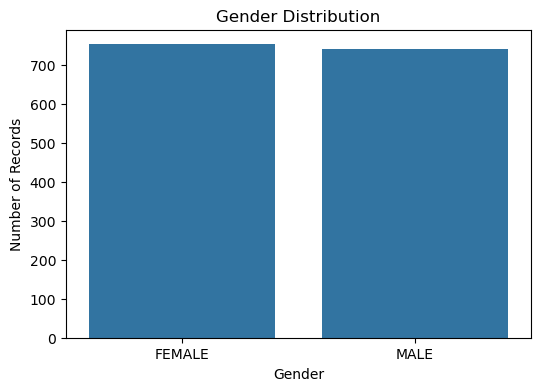

In [18]:
# 11. GENDER DISTRIBUTION

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="gender")

plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Records")

plt.show()

### Gender Distribution
- The dataset contains 753 female records (50.40%) and 741 male records (49.60%) with available gender information.
- The distribution is relatively balanced between the two categories.
- However, 804 records (approximately 35%) have missing gender information.

### EDA - REGION VARIABLES

In [19]:
# 12. REGION DISTRIBUTION
# Count records in each region
print(df["region"].value_counts())

region
FACE       570
FOREARM    392
CHEST      280
BACK       248
ARM        192
NOSE       158
HAND       126
NECK        93
THIGH       73
EAR         73
ABDOMEN     36
LIP         23
SCALP       18
FOOT        16
Name: count, dtype: int64


In [20]:
# Calculate the percentage of records in each region
print(df["region"].value_counts(normalize=True) * 100)

region
FACE       24.804178
FOREARM    17.058312
CHEST      12.184508
BACK       10.791993
ARM         8.355091
NOSE        6.875544
HAND        5.483029
NECK        4.046997
THIGH       3.176675
EAR         3.176675
ABDOMEN     1.566580
LIP         1.000870
SCALP       0.783290
FOOT        0.696258
Name: proportion, dtype: float64


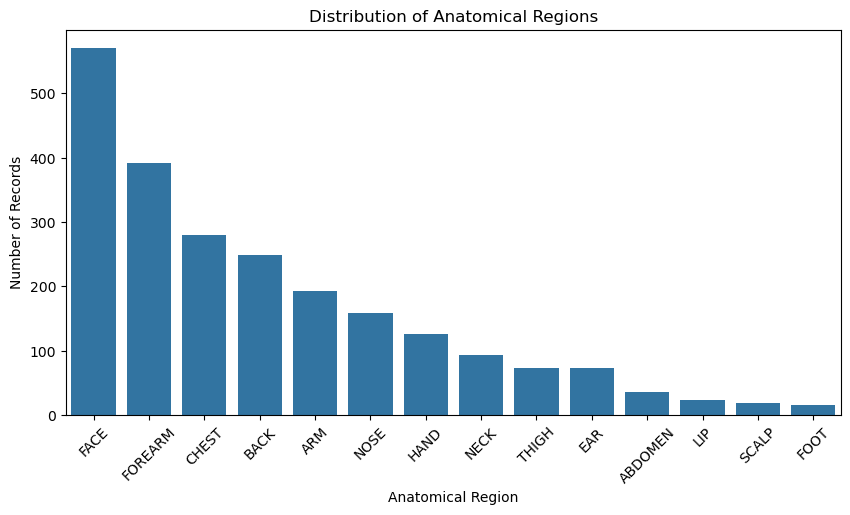

In [21]:
# 13. REGION DISTRIBUTION VISUALISATION

plt.figure(figsize=(10, 5))

sns.countplot(data=df, x="region", order=df["region"].value_counts().index)

plt.title("Distribution of Anatomical Regions")
plt.xlabel("Anatomical Region")
plt.ylabel("Number of Records")

plt.xticks(rotation=45)

plt.show()

### Region Distribution
- The dataset contains 14 anatomical regions.
- Face is the most represented region (24.80%), followed by forearm (17.06%).
- Foot is the least represented region (0.70%).
- The distribution across anatomical regions is uneven, which may be relevant when evaluating model performance.

### EDA - SMOKING VARIABLES

In [22]:
# 14. SMOKING DISTRIBUTION
# Count records in each smoking category
print(df["smoke"].value_counts())

smoke
False    1292
True      202
Name: count, dtype: int64


In [23]:
# Calculate percentages
print(df["smoke"].value_counts(normalize=True) * 100)

smoke
False    86.47925
True     13.52075
Name: proportion, dtype: float64


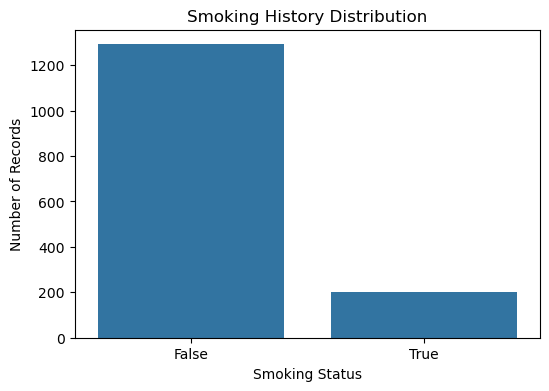

In [24]:
# 15. SMOKING DISTRIBUTION VISUALISATION

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="smoke")

plt.title("Smoking History Distribution")
plt.xlabel("Smoking Status")
plt.ylabel("Number of Records")

plt.show()

### Smoking Distribution
- 1,292 records (86.48%) are classified as False.
- 202 records (13.52%) are classified as True.
- The distribution is imbalanced, with substantially more False than True records.
- 804 records have missing smoking information.

### EDA - DRINKING VARIABLES

In [25]:
# 14. SMOKING DISTRIBUTION
# Count records in each smoking category
print(df["smoke"].value_counts())

smoke
False    1292
True      202
Name: count, dtype: int64


In [26]:
# Calculate percentages
print(df["smoke"].value_counts(normalize=True) * 100)

smoke
False    86.47925
True     13.52075
Name: proportion, dtype: float64


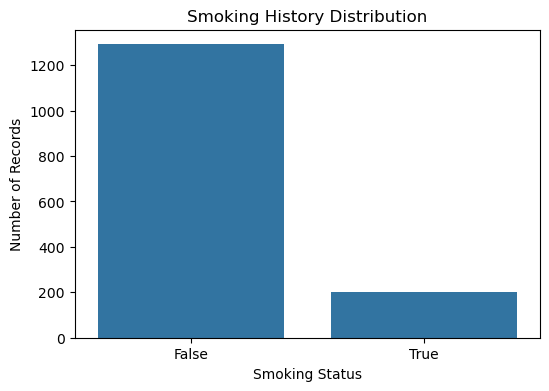

In [27]:
# 15. SMOKING DISTRIBUTION VISUALISATION

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="smoke")

plt.title("Smoking History Distribution")
plt.xlabel("Smoking Status")
plt.ylabel("Number of Records")

plt.show()

### Smoking Distribution
- 1,292 records (86.48%) are classified as False.
- 202 records (13.52%) are classified as True.
- The distribution is imbalanced, with substantially more False than True records.
- 804 records have missing smoking information.

### EDA - DRINKING VARIABLES

In [28]:
# 16. DRINKING DISTRIBUTION

# Count records in each drinking category
print(df["drink"].value_counts())

drink
False    1126
True      368
Name: count, dtype: int64


In [29]:
# Calculate percentages
print(df["drink"].value_counts(normalize=True) * 100)

drink
False    75.368139
True     24.631861
Name: proportion, dtype: float64


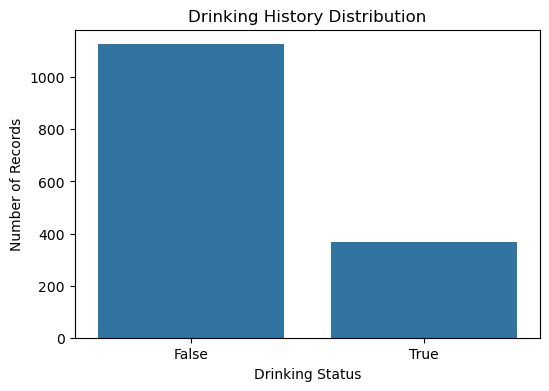

In [30]:
# 17. DRINKING DISTRIBUTION VISUALISATION

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="drink")

plt.title("Drinking History Distribution")
plt.xlabel("Drinking Status")
plt.ylabel("Number of Records")

plt.show()

### Drinking Distribution
- 1,126 records (75.37%) are classified as False.
- 368 records (24.63%) are classified as True.
- The distribution is somewhat imbalanced, with more records classified as False.
- 804 records have missing drinking information.

### EDA - FATHER'S BACKGROUND

In [31]:
# 18. FATHER'S BACKGROUND DISTRIBUTION

print(df["background_father"].value_counts())

background_father
POMERANIA      530
GERMANY        466
ITALY          250
UNK             95
BRAZIL          89
NETHERLANDS     19
PORTUGAL        15
POLAND           7
BRASIL           3
CZECH            3
AUSTRIA          1
SPAIN            1
ISRAEL           1
Name: count, dtype: int64


In [32]:
# Calculate percentages
print(df["background_father"].value_counts(normalize=True) * 100)

background_father
POMERANIA      35.810811
GERMANY        31.486486
ITALY          16.891892
UNK             6.418919
BRAZIL          6.013514
NETHERLANDS     1.283784
PORTUGAL        1.013514
POLAND          0.472973
BRASIL          0.202703
CZECH           0.202703
AUSTRIA         0.067568
SPAIN           0.067568
ISRAEL          0.067568
Name: proportion, dtype: float64


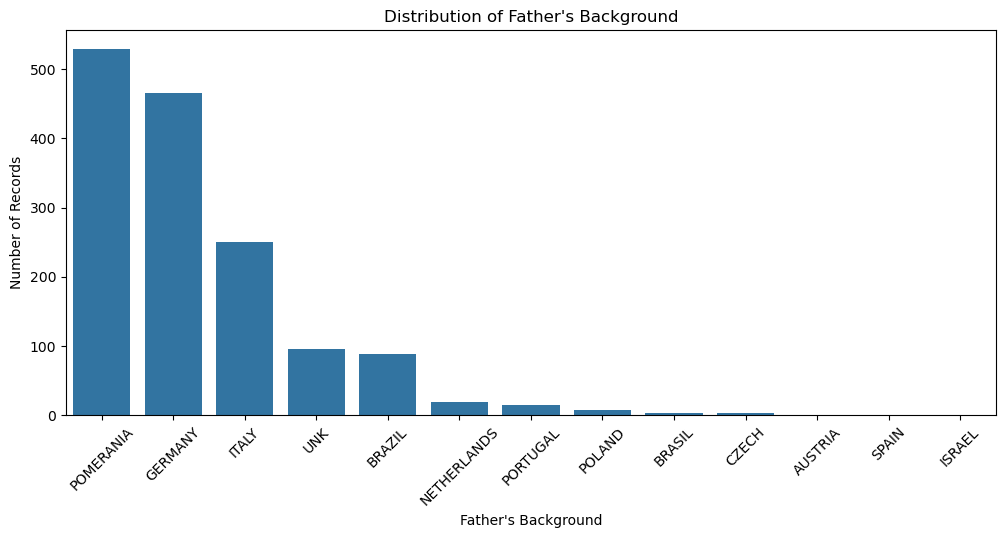

In [33]:
# 19. FATHER'S BACKGROUND VISUALISATION

plt.figure(figsize=(12, 5))

sns.countplot(
    data=df,
    x="background_father",
    order=df["background_father"].value_counts().index
)

plt.title("Distribution of Father's Background")
plt.xlabel("Father's Background")
plt.ylabel("Number of Records")

plt.xticks(rotation=45)

plt.show()

### Father's Background Distribution
- POMERANIA is the most frequent category (35.81%), followed by GERMANY (31.49%) and ITALY (16.89%).
- These three categories account for approximately 84.19% of available records.
- UNK represents 6.42% of records and may indicate unknown information.
- BRAZIL and BRASIL appear as separate categories, suggesting a possible inconsistency in category naming.
- Several categories have very few observations, resulting in an uneven distribution.

### EDA - MOTHER'S BACKGROUND

In [34]:
# 20. MOTHER'S BACKGROUND DISTRIBUTION
# Count records in each category
print(df["background_mother"].value_counts())

background_mother
POMERANIA      533
GERMANY        482
ITALY          236
UNK             84
BRAZIL          81
PORTUGAL        20
NETHERLANDS     20
POLAND           9
NORWAY           7
FRANCE           2
SPAIN            2
Name: count, dtype: int64


In [35]:
# Calculate percentages
print(df["background_mother"].value_counts(normalize=True) * 100)

background_mother
POMERANIA      36.111111
GERMANY        32.655827
ITALY          15.989160
UNK             5.691057
BRAZIL          5.487805
PORTUGAL        1.355014
NETHERLANDS     1.355014
POLAND          0.609756
NORWAY          0.474255
FRANCE          0.135501
SPAIN           0.135501
Name: proportion, dtype: float64


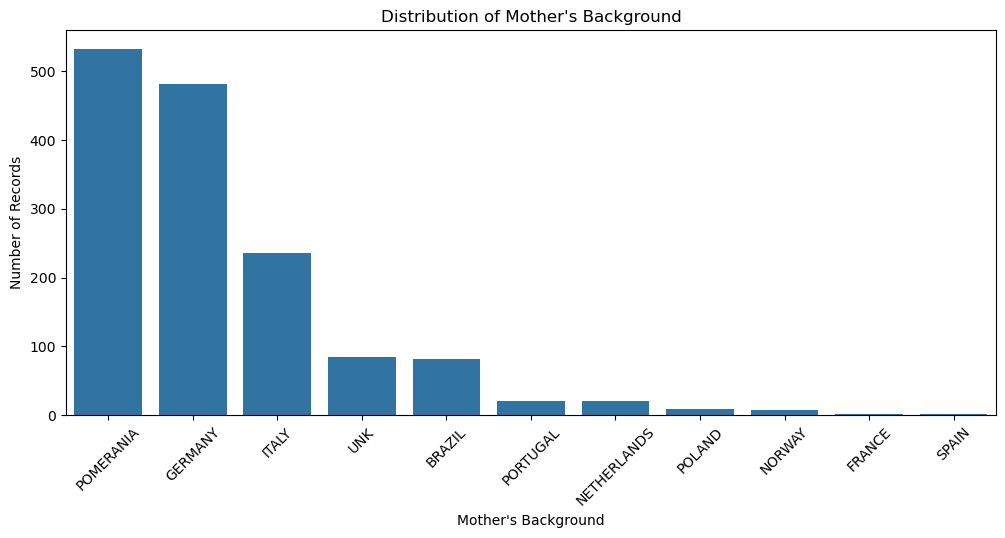

In [36]:
# 21. MOTHER'S BACKGROUND VISUALISATION

plt.figure(figsize=(12, 5))

sns.countplot(
    data=df,
    x="background_mother",
    order=df["background_mother"].value_counts().index
)

plt.title("Distribution of Mother's Background")
plt.xlabel("Mother's Background")
plt.ylabel("Number of Records")

plt.xticks(rotation=45)

plt.show()

### Mother's Background Distribution¶
POMERANIA is the most frequent category (36.11%), followed by GERMANY (32.66%) and ITALY (15.99%).
These three categories account for approximately 84.76% of available records.
UNK represents 5.69% of records and may indicate unknown information.
FRANCE and SPAIN have very few observations.
The distribution is concentrated in a small number of categories.

### EDA - PESTICIDE EXPOSURE 

In [37]:
# 22. PESTICIDE EXPOSURE DISTRIBUTION

print(df["pesticide"].value_counts())

print(df["pesticide"].value_counts(normalize=True) * 100)

pesticide
False    897
True     597
Name: count, dtype: int64
pesticide
False    60.040161
True     39.959839
Name: proportion, dtype: float64


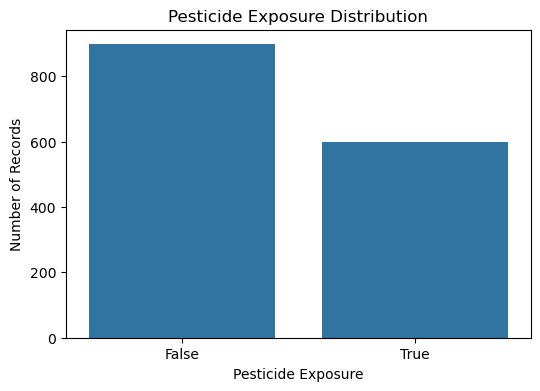

In [38]:
# 23. PESTICIDE EXPOSURE VISUALISATION

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="pesticide")

plt.title("Pesticide Exposure Distribution")
plt.xlabel("Pesticide Exposure")
plt.ylabel("Number of Records")

plt.show()

### Pesticide Exposure Distribution
- 897 records (60.04%) are classified as False.
- 597 records (39.96%) are classified as True.
- The distribution is relatively balanced compared with some other categorical variables.
- 804 records have missing pesticide information.

### EDA - SKIN CANCER HISTORY

In [39]:
# 24. SKIN CANCER HISTORY DISTRIBUTION

print(df["skin_cancer_history"].value_counts())

print(df["skin_cancer_history"].value_counts(normalize=True) * 100)

skin_cancer_history
False    813
True     681
Name: count, dtype: int64
skin_cancer_history
False    54.417671
True     45.582329
Name: proportion, dtype: float64


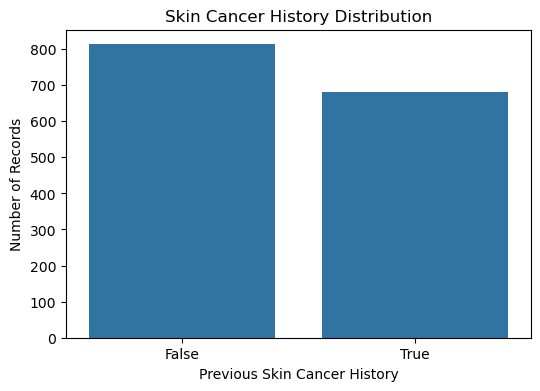

In [40]:
# 25. SKIN CANCER HISTORY VISUALISATION

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="skin_cancer_history")

plt.title("Skin Cancer History Distribution")
plt.xlabel("Previous Skin Cancer History")
plt.ylabel("Number of Records")

plt.show()

### Skin Cancer History Distribution
813 records (54.42%) are classified as False.
681 records (45.58%) are classified as True.
The distribution is relatively balanced.
804 records have missing information.
This variable represents previous skin cancer history and should be distinguished from the current diagnosis.

### EDA - CANCER HISTORY

In [41]:
# 26. CANCER HISTORY DISTRIBUTION

print(df["cancer_history"].value_counts())

print(df["cancer_history"].value_counts(normalize=True) * 100)

cancer_history
True     779
False    715
Name: count, dtype: int64
cancer_history
True     52.141901
False    47.858099
Name: proportion, dtype: float64


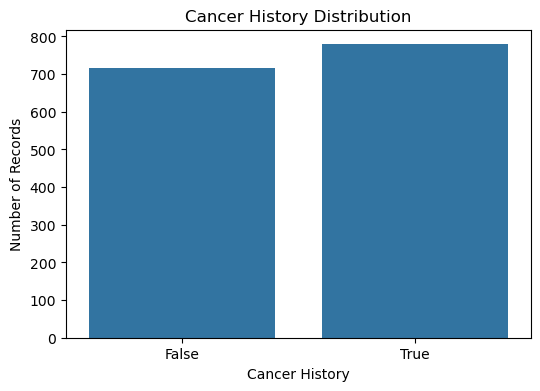

In [42]:
# 27. CANCER HISTORY VISUALISATION

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="cancer_history")

plt.title("Cancer History Distribution")
plt.xlabel("Cancer History")
plt.ylabel("Number of Records")

plt.show()

### Cancer History Distribution
- 779 records (52.14%) are classified as True.
- 715 records (47.86%) are classified as False.
- The distribution is relatively balanced.
- 804 records have missing information.
- This variable should be distinguished from skin_cancer_history, as the two may represent different types of medical history.

### EDA - PIPED WATER DISTRIBUTION

In [45]:
# 28. PIPED WATER DISTRIBUTION

print(df["has_piped_water"].value_counts())

print(df["has_piped_water"].value_counts(normalize=True) * 100)

has_piped_water
True     923
False    571
Name: count, dtype: int64
has_piped_water
True     61.780455
False    38.219545
Name: proportion, dtype: float64


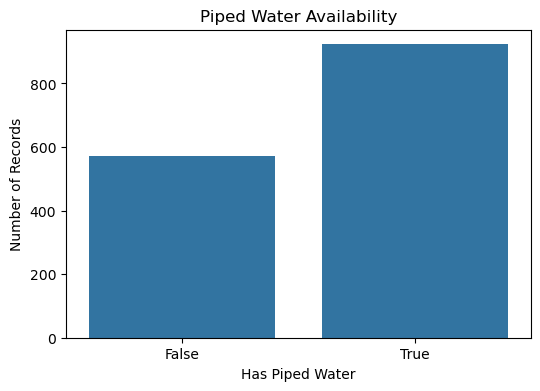

In [46]:
# 29. PIPED WATER DISTRIBUTION VISUALISATION

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="has_piped_water")

plt.title("Piped Water Availability")
plt.xlabel("Has Piped Water")
plt.ylabel("Number of Records")

plt.show()

### Piped Water Distribution
- 923 records (61.78%) are classified as True.
- 571 records (38.22%) are classified as False.
- The distribution is moderately uneven.
- 804 records have missing information.

### EDA - SEWAGE SYSTEM DISTRIBUTION

In [47]:
# 30. SEWAGE SYSTEM DISTRIBUTION

print(df["has_sewage_system"].value_counts())

print(df["has_sewage_system"].value_counts(normalize=True) * 100)

has_sewage_system
True     846
False    648
Name: count, dtype: int64
has_sewage_system
True     56.626506
False    43.373494
Name: proportion, dtype: float64


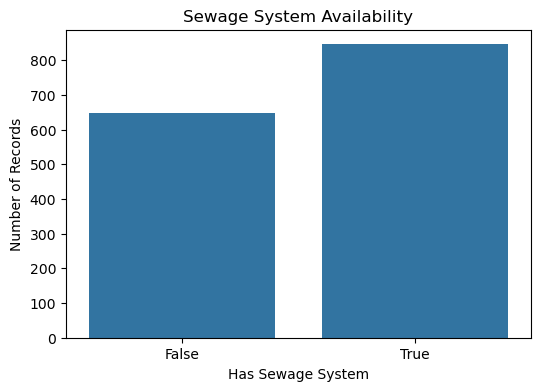

In [48]:
# 31. SEWAGE SYSTEM DISTRIBUTION VISUALISATION

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="has_sewage_system")

plt.title("Sewage System Availability")
plt.xlabel("Has Sewage System")
plt.ylabel("Number of Records")

plt.show()

### Sewage System Distribution
- 846 records (56.63%) are classified as True.
- 648 records (43.37%) are classified as False.
- The distribution is relatively balanced.
- 804 records have missing information.

### EDA - FITSPATRICK

In [49]:
# 32. FITZPATRICK SKIN TYPE DISTRIBUTION

print(df["fitspatrick"].value_counts())

print(df["fitspatrick"].value_counts(normalize=True) * 100)

fitspatrick
2.0    876
3.0    392
1.0    153
4.0     62
5.0     10
6.0      1
Name: count, dtype: int64
fitspatrick
2.0    58.634538
3.0    26.238286
1.0    10.240964
4.0     4.149933
5.0     0.669344
6.0     0.066934
Name: proportion, dtype: float64


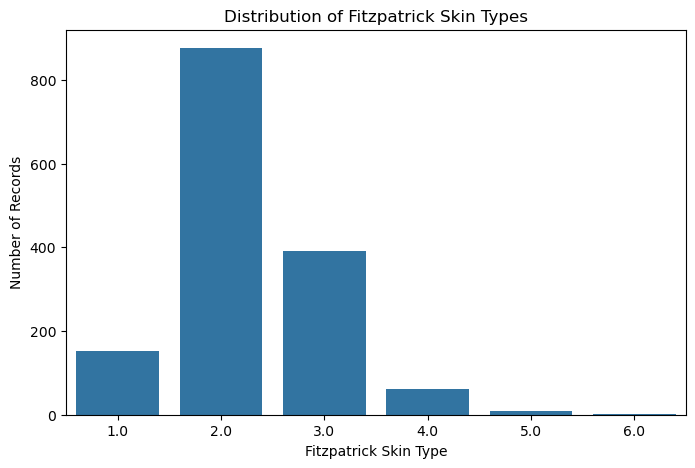

In [50]:
# 33. FITZPATRICK SKIN TYPE VISUALISATION

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="fitspatrick",
    order=sorted(df["fitspatrick"].dropna().unique())
)

plt.title("Distribution of Fitzpatrick Skin Types")
plt.xlabel("Fitzpatrick Skin Type")
plt.ylabel("Number of Records")

plt.show()

It refers to the Fitzpatrick skin phototype scale, which classifies skin according to its response to sunlight, particularly its tendency to burn or tan.

It has six types, ranging from Type I to Type VI.

### Fitzpatrick Skin Type Distribution
- Type II is the most frequent category (58.63%), followed by Type III (26.24%).
- Types II and III account for approximately 84.87% of available records.
- Type VI is extremely underrepresented, with only one observation.
- The distribution is highly concentrated in Types II and III.
- Fitzpatrick skin type is an ordinal categorical variable because the categories have a meaningful order (I to VI).

### EDA - ITCH DISTRIBUTION

In [51]:
# 34. ITCH DISTRIBUTION

# Count records in each category
print(df["itch"].value_counts())

# Calculate percentages
print(df["itch"].value_counts(normalize=True) * 100)

itch
TRUE     1455
FALSE     837
UNK         6
Name: count, dtype: int64
itch
TRUE     63.315927
FALSE    36.422977
UNK       0.261097
Name: proportion, dtype: float64


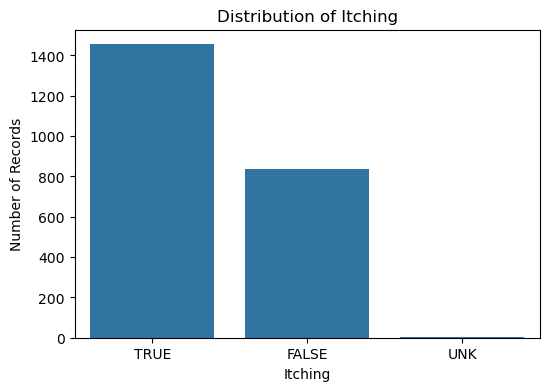

In [52]:
# 35. ITCH DISTRIBUTION VISUALISATION

plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="itch",
    order=df["itch"].value_counts().index
)

plt.title("Distribution of Itching")
plt.xlabel("Itching")
plt.ylabel("Number of Records")

plt.show()

#### Itch Distribution
- TRUE represents 63.32% of records, while FALSE represents 36.42%.
- Only 6 records (0.26%) are classified as UNK.
- The variable has three categories and no missing values.
- UNK represents an explicit unknown category that may require consideration during preprocessing.

### EDA - GREW DISTRIBUTION

In [53]:
# 36. LESION GROWTH DISTRIBUTION

print(df["grew"].value_counts())

print(df["grew"].value_counts(normalize=True) * 100)

grew
FALSE    971
TRUE     925
UNK      402
Name: count, dtype: int64
grew
FALSE    42.254134
TRUE     40.252393
UNK      17.493473
Name: proportion, dtype: float64


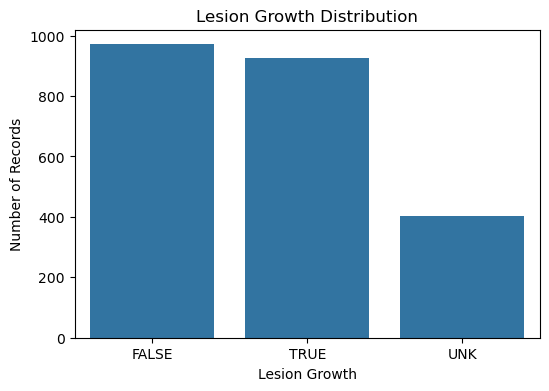

In [54]:
# 37. LESION GROWTH DISTRIBUTION VISUALISATION

plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="grew",
    order=df["grew"].value_counts().index
)

plt.title("Lesion Growth Distribution")
plt.xlabel("Lesion Growth")
plt.ylabel("Number of Records")

plt.show()

### Lesion Growth Distribution
- 971 records (42.25%) are classified as FALSE.
- 925 records (40.25%) are classified as TRUE.
- 402 records (17.49%) are classified as UNK.
- The TRUE and FALSE categories are relatively balanced.
- A considerable proportion of records have an explicitly unknown growth status.

### EDA - HURT

In [55]:
# 38. LESION PAIN DISTRIBUTION

print(df["hurt"].value_counts())

print(df["hurt"].value_counts(normalize=True) * 100)

hurt
FALSE    1891
TRUE      397
UNK        10
Name: count, dtype: int64
hurt
FALSE    82.288947
TRUE     17.275892
UNK       0.435161
Name: proportion, dtype: float64


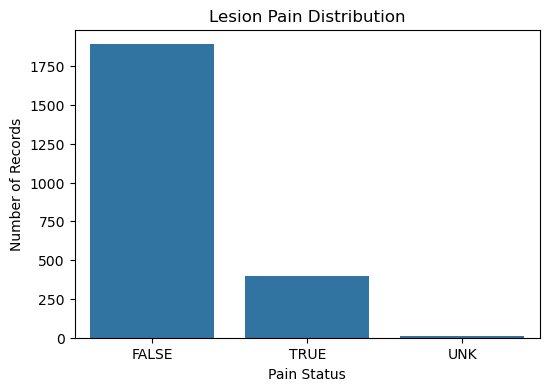

In [56]:
# 39. LESION PAIN DISTRIBUTION VISUALISATION

plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="hurt",
    order=df["hurt"].value_counts().index
)

plt.title("Lesion Pain Distribution")
plt.xlabel("Pain Status")
plt.ylabel("Number of Records")

plt.show()

### Lesion Pain Distribution
- 1,891 records (82.29%) are classified as FALSE.
- 397 records (17.28%) are classified as TRUE.
- 10 records (0.44%) are classified as UNK.
- The distribution is heavily concentrated in the FALSE category.
- The variable contains an explicitly unknown category.

### EDA - CHANGED

In [58]:
# 40. LESION CHANGE DISTRIBUTION

print(df["changed"].value_counts())

print(df["changed"].value_counts(normalize=True) * 100)

changed
FALSE    1700
UNK       396
TRUE      202
Name: count, dtype: int64
changed
FALSE    73.977372
UNK      17.232376
TRUE      8.790252
Name: proportion, dtype: float64


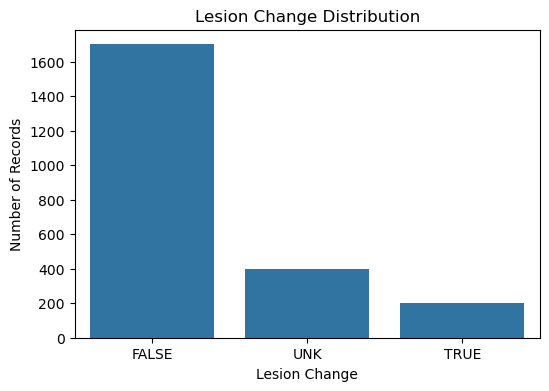

In [59]:
# 41. LESION CHANGE DISTRIBUTION VISUALISATION

plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="changed",
    order=df["changed"].value_counts().index
)

plt.title("Lesion Change Distribution")
plt.xlabel("Lesion Change")
plt.ylabel("Number of Records")

plt.show()

### Lesion Change Distribution
- 1,700 records (73.98%) are classified as FALSE.
- 202 records (8.79%) are classified as TRUE.
- 396 records (17.23%) are classified as UNK.
- The distribution is heavily concentrated in FALSE.
- A considerable proportion of records have an explicitly unknown status.

### EDA - BLEED

In [60]:
# 42. LESION BLEEDING DISTRIBUTION

print(df["bleed"].value_counts())

print(df["bleed"].value_counts(normalize=True) * 100)

bleed
FALSE    1678
TRUE      614
UNK         6
Name: count, dtype: int64
bleed
FALSE    73.020017
TRUE     26.718886
UNK       0.261097
Name: proportion, dtype: float64


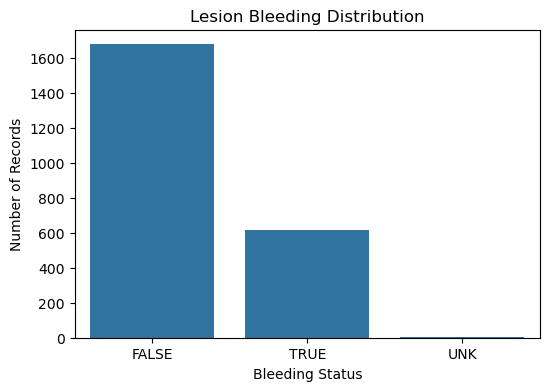

In [61]:
# 43. LESION BLEEDING DISTRIBUTION VISUALISATION

plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="bleed",
    order=df["bleed"].value_counts().index
)

plt.title("Lesion Bleeding Distribution")
plt.xlabel("Bleeding Status")
plt.ylabel("Number of Records")

plt.show()

### Lesion Bleeding Distribution
- 1,678 records (73.02%) are classified as FALSE.
- 614 records (26.72%) are classified as TRUE.
- 6 records (0.26%) are classified as UNK.
- The distribution is concentrated in FALSE.
- The variable contains an explicitly unknown category.

### EDA - ELEVATION

In [62]:
# 44. LESION ELEVATION DISTRIBUTION

print(df["elevation"].value_counts())

print(df["elevation"].value_counts(normalize=True) * 100)

elevation
TRUE     1433
FALSE     863
UNK         2
Name: count, dtype: int64
elevation
TRUE     62.358573
FALSE    37.554395
UNK       0.087032
Name: proportion, dtype: float64


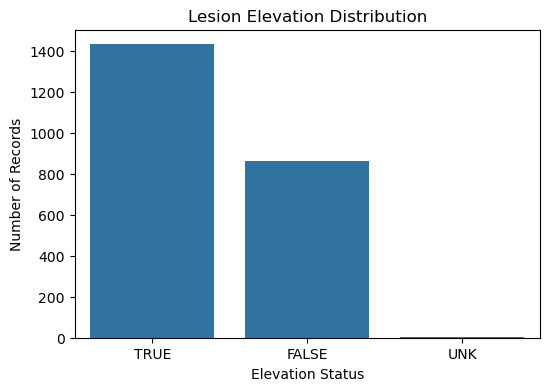

In [63]:
# 45. LESION ELEVATION DISTRIBUTION VISUALISATION

plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="elevation",
    order=df["elevation"].value_counts().index
)

plt.title("Lesion Elevation Distribution")
plt.xlabel("Elevation Status")
plt.ylabel("Number of Records")

plt.show()

### Lesion Elevation Distribution
- 1,433 records (62.36%) are classified as TRUE.
- 863 records (37.55%) are classified as FALSE.
- Only 2 records (0.09%) are classified as UNK.
- The distribution is moderately concentrated in TRUE.

### EDA - BIOPSY

In [64]:
# 46. BIOPSY DISTRIBUTION

print(df["biopsed"].value_counts())

print(df["biopsed"].value_counts(normalize=True) * 100)

biopsed
True     1342
False     956
Name: count, dtype: int64
biopsed
True     58.398607
False    41.601393
Name: proportion, dtype: float64


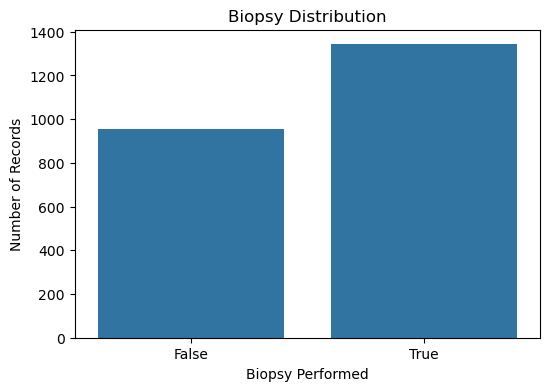

In [65]:
# 47. BIOPSY DISTRIBUTION VISUALISATION

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="biopsed")

plt.title("Biopsy Distribution")
plt.xlabel("Biopsy Performed")
plt.ylabel("Number of Records")

plt.show()

### Biopsy Distribution
- 1,342 records (58.40%) are classified as True.
- 956 records (41.60%) are classified as False.
- The distribution is relatively balanced.
- There are no missing values.

### EDA - DIAGNOSTIC

In [66]:
# 48. DIAGNOSTIC DISTRIBUTION

# Count records in each diagnostic category
print(df["diagnostic"].value_counts())

# Calculate percentages
print(df["diagnostic"].value_counts(normalize=True) * 100)

diagnostic
BCC    845
ACK    730
NEV    244
SEK    235
SCC    192
MEL     52
Name: count, dtype: int64
diagnostic
BCC    36.771105
ACK    31.766754
NEV    10.617929
SEK    10.226284
SCC     8.355091
MEL     2.262837
Name: proportion, dtype: float64


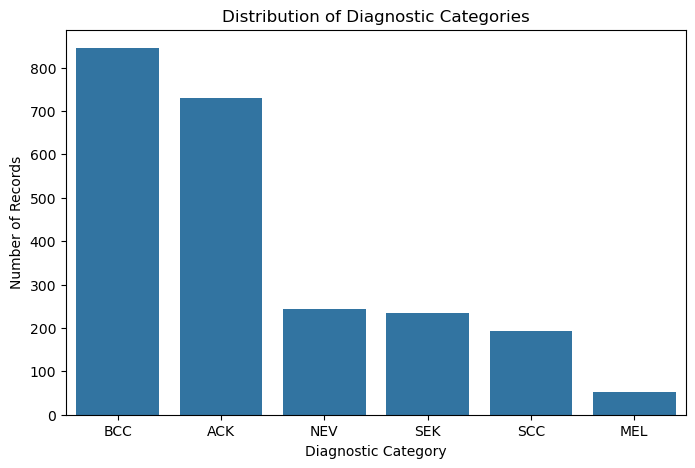

In [67]:
# 49. DIAGNOSTIC DISTRIBUTION

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="diagnostic",
              order=df["diagnostic"].value_counts().index)

plt.title("Distribution of Diagnostic Categories")
plt.xlabel("Diagnostic Category")
plt.ylabel("Number of Records")

plt.show()

### Diagnostic Distribution

The target variable contains six diagnostic categories. 
BCC is the most frequent category, representing approximately 
36.77% of the dataset, followed by ACK at 31.77%.

MEL is the least represented category, accounting for only 
2.26% of the records.

The distribution indicates class imbalance. This may affect 
model performance, particularly when predicting minority 
classes. Therefore, accuracy alone may not be a sufficient 
evaluation metric. We will also consider precision, recall, 
F1-score and the confusion matrix.

# Stage 3 - Exploratory Data Analysis - Bivariate Analysis

### EDA - GENDER VS DIAGNOSIS

In [68]:
# BIVARIATE ANALYSIS
# GENDER VS DIAGNOSTIC

# 50. Create a cross-tabulation
pd.crosstab(df["gender"], df["diagnostic"])

diagnostic,ACK,BCC,MEL,NEV,SCC,SEK
gender,,,,,,
FEMALE,153,406,28,49,90,27
MALE,130,439,24,26,102,20


### A few observations:
- BCC is the most frequent diagnosis in both groups.
- BCC has more male records (439) than female records (406).
- NEV has almost twice as many female records (49) as male records (26).
- SCC has more male records (102) than female records (90).
- MEL has relatively few records in both groups.

In [69]:
# 51. Calculate percentages within each gender
pd.crosstab(
    df["gender"],
    df["diagnostic"],
    normalize="index"
) * 100

diagnostic,ACK,BCC,MEL,NEV,SCC,SEK
gender,,,,,,
FEMALE,20.318725,53.917663,3.718459,6.507304,11.952191,3.585657
MALE,17.543860,59.244265,3.238866,3.508772,13.765182,2.699055


A cross-tabulation was used to examine the relationship between 
gender and diagnostic category.

BCC was the most frequent diagnosis in both gender groups.
It represented 53.92% of female records and 59.24% of male records.

ACK and NEV represented a higher proportion of female records,
while BCC and SCC represented a higher proportion of male records.

These observations suggest differences in diagnostic distributions
between the two groups. However, further statistical analysis would
be required to determine whether these associations are significant.

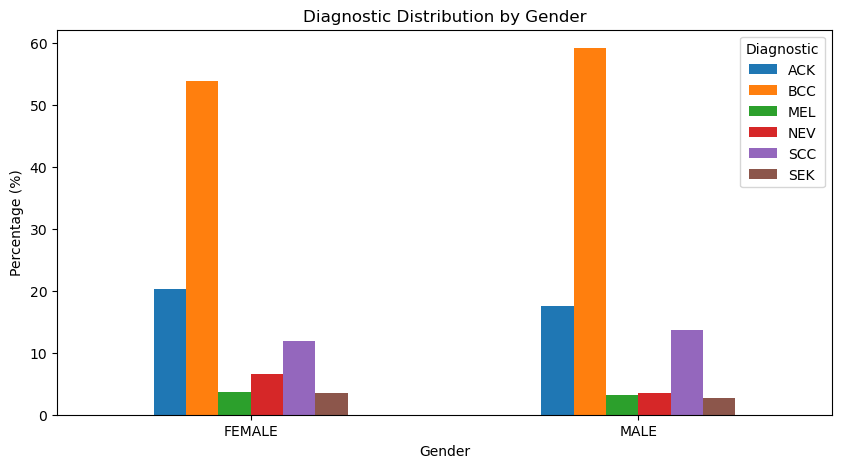

In [70]:
# 52. GENDER VS DIAGNOSTIC - BAR CHART

gender_diagnosis = pd.crosstab(
    df["gender"],
    df["diagnostic"],
    normalize="index"
) * 100

gender_diagnosis.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Diagnostic Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Diagnostic")
plt.show()

### EDA - REGION VS DIAGNOSTIC

In [71]:
# 53. REGION VS DIAGNOSTIC

# Count records for each region and diagnostic category
pd.crosstab(df["region"], df["diagnostic"])

diagnostic,ACK,BCC,MEL,NEV,SCC,SEK
region,,,,,,
ABDOMEN,3,2,2,19,2,8
ARM,91,44,7,10,21,19
BACK,16,91,14,86,17,24
CHEST,60,135,5,29,20,31
EAR,11,36,2,3,13,8
FACE,139,260,5,38,29,99
FOOT,4,0,0,6,6,0
FOREARM,261,67,5,10,28,21
HAND,78,19,2,6,19,2


In [72]:
# 54. Calculate percentages within each body region
pd.crosstab(
    df["region"],
    df["diagnostic"],
    normalize="index"
) * 100

diagnostic,ACK,BCC,MEL,NEV,SCC,SEK
region,,,,,,
ABDOMEN,8.333333,5.555556,5.555556,52.777778,5.555556,22.222222
ARM,47.395833,22.916667,3.645833,5.208333,10.937500,9.895833
BACK,6.451613,36.693548,5.645161,34.677419,6.854839,9.677419
CHEST,21.428571,48.214286,1.785714,10.357143,7.142857,11.071429
EAR,15.068493,49.315068,2.739726,4.109589,17.808219,10.958904
FACE,24.385965,45.614035,0.877193,6.666667,5.087719,17.368421
FOOT,25.000000,0.000000,0.000000,37.500000,37.500000,0.000000
FOREARM,66.581633,17.091837,1.275510,2.551020,7.142857,5.357143
HAND,61.904762,15.079365,1.587302,4.761905,15.079365,1.587302


### Region vs Diagnostic Category

A cross-tabulation was used to investigate the relationship 
between lesion location and diagnostic category.

The results show differences in diagnostic distributions 
across body regions.

ACK represented the largest proportion of records on the 
forearm (66.58%) and hand (61.90%), whereas BCC was the 
largest category on the nose (77.85%), ear (49.32%), 
chest (48.21%) and face (45.61%).

NEV represented 52.78% of abdomen records and 50% of 
scalp records. However, these regions had relatively 
small sample sizes.

The findings suggest that lesion location may be a useful 
feature to investigate during classification. However, 
these descriptive results do not establish causation.

### EDA - AGE VS DIAGNOSITC

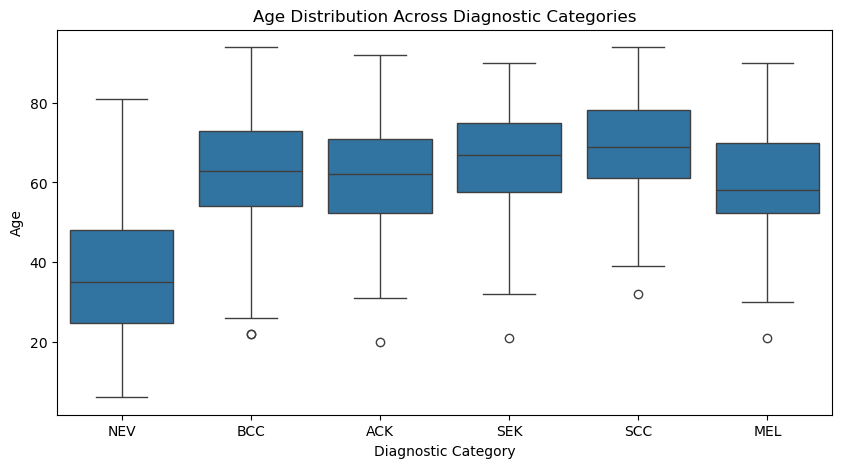

In [73]:
# 55. AGE VS DIAGNOSTIC

plt.figure(figsize=(10, 5))

sns.boxplot(data=df, x="diagnostic", y="age")

plt.title("Age Distribution Across Diagnostic Categories")
plt.xlabel("Diagnostic Category")
plt.ylabel("Age")

plt.show()

In [74]:
# 56. Age statistics for each diagnostic category
df.groupby("diagnostic")["age"].describe()

,count,mean,std,min,25%,50%,75%,max
diagnostic,,,,,,,,
ACK,730.0,61.749315,12.696042,20.0,52.25,62.0,71.00,92.0
BCC,845.0,63.146746,13.459515,22.0,54.00,63.0,73.00,94.0
MEL,52.0,59.826923,13.865914,21.0,52.25,58.0,70.00,90.0
NEV,244.0,35.643443,15.581193,6.0,24.75,35.0,48.00,81.0
SCC,192.0,68.864583,12.210304,32.0,61.00,69.0,78.25,94.0
SEK,235.0,65.880851,12.155802,21.0,57.50,67.0,75.00,90.0


### Age vs Diagnostic Category

Age statistics were grouped by diagnostic category to examine 
differences in age distributions.

SCC had the highest mean age (68.86), followed by SEK (65.88) 
and BCC (63.15).

NEV had a considerably lower mean age of 35.64 compared with 
the other diagnostic categories.

The median age followed a similar pattern, with NEV at 35 
and SCC at 69.

These observations suggest that age may be a useful feature 
for distinguishing between diagnostic categories. However, 
further model evaluation is required to determine its predictive value.

### EDA - Fitzpatrick skin type vs diagnosis

In [76]:
# 57. FITZPATRICK SKIN TYPE VS DIAGNOSTIC

pd.crosstab(
    df["fitspatrick"],
    df["diagnostic"]
)

diagnostic,ACK,BCC,MEL,NEV,SCC,SEK
fitspatrick,,,,,,
1.0,25,101,3,4,16,4
2.0,156,502,35,34,126,23
3.0,89,217,10,24,45,7
4.0,10,22,4,12,3,11
5.0,3,3,0,1,2,1
6.0,0,0,0,0,0,1


### A few observations:
- Type II has the highest number of records across the dataset.
- BCC is the most frequent diagnosis for Types I, II and III.
- Type IV has a more varied distribution, with BCC (22) and NEV (12) among its more frequent categories.
- Type V has very few records (10 in total).
- Type VI has only one record, classified as SEK.
- Note, these are raw counts. Type II has many more records than the other skin types, so we should calculate percentages before comparing distributions.

In [77]:
# 58. Calculate percentages within each Fitzpatrick skin type
pd.crosstab(
    df["fitspatrick"],
    df["diagnostic"],
    normalize="index"
) * 100

diagnostic,ACK,BCC,MEL,NEV,SCC,SEK
fitspatrick,,,,,,
1.0,16.339869,66.013072,1.960784,2.614379,10.457516,2.614379
2.0,17.808219,57.305936,3.995434,3.881279,14.383562,2.625571
3.0,22.704082,55.357143,2.551020,6.122449,11.479592,1.785714
4.0,16.129032,35.483871,6.451613,19.354839,4.838710,17.741935
5.0,30.000000,30.000000,0.000000,10.000000,20.000000,10.000000
6.0,0.000000,0.000000,0.000000,0.000000,0.000000,100.000000


# Fitzpatrick Skin Type vs Diagnostic Category

A cross-tabulation was used to investigate the relationship 
between Fitzpatrick skin type and diagnostic category.

BCC was the most frequent diagnosis among Types I, II, III 
and IV. Its proportion decreased from 66.01% in Type I 
to 35.48% in Type IV.

Type IV showed a more varied distribution of diagnostic 
categories compared with Types I–III.

Types V and VI had very small sample sizes (10 and 1 
records respectively). Therefore, their percentages should 
be interpreted cautiously.

These observations suggest that Fitzpatrick skin type may 
be worth investigating as a predictive feature. However, 
further model evaluation is required.

### EDA - Lesion Diameter 1 vs Diagnosis

In [78]:
# 59. DIAMETER 1 VS DIAGNOSTIC

df.groupby("diagnostic")["diameter_1"].describe()

,count,mean,std,min,25%,50%,75%,max
diagnostic,,,,,,,,
ACK,283.0,10.978799,7.108050,1.0,6.00,10.0,13.0,50.0
BCC,845.0,12.049941,8.118752,0.0,7.00,10.0,15.0,100.0
MEL,52.0,15.153846,7.606459,5.0,9.00,13.5,20.0,40.0
NEV,75.0,12.133333,17.510100,2.0,5.00,7.0,10.0,89.0
SCC,192.0,12.223958,8.407604,0.0,7.75,10.0,15.0,90.0
SEK,47.0,9.361702,5.006194,3.0,6.00,8.0,12.5,25.0


### Diameter 1 vs Diagnostic Category

Descriptive statistics were calculated to compare diameter_1 
across the six diagnostic categories.

MEL had the highest mean diameter (15.15) and median (13.5), 
while SEK had the lowest mean (9.36) and median (8).

NEV showed considerable variability, with a standard deviation 
of 17.51 and a maximum value of 89, despite a median of 7.

Large maximum values were also observed for BCC (100) and 
SCC (90), suggesting potential extreme values that require 
further investigation.

Only 1,494 records had available diameter_1 measurements, 
with 804 missing values.

### EDA - Lesion Diameter 2 vs Diagnosis

In [79]:
# 60. DIAMETER 2 VS DIAGNOSTIC

df.groupby("diagnostic")["diameter_2"].describe()

,count,mean,std,min,25%,50%,75%,max
diagnostic,,,,,,,,
ACK,283.0,8.187279,5.220348,1.0,5.0,7.0,10.00,48.0
BCC,845.0,9.022722,6.017097,0.0,5.0,8.0,11.00,70.0
MEL,52.0,11.173077,6.498027,3.0,7.0,10.0,12.50,34.0
NEV,75.0,7.346667,6.636291,2.0,4.0,5.0,8.50,40.0
SCC,192.0,9.515625,5.117444,0.0,6.0,8.0,12.25,33.0
SEK,47.0,6.914894,3.775377,2.0,4.0,6.0,8.50,15.0


### Diameter 2 vs Diagnostic Category

Descriptive statistics were calculated to compare diameter_2 
across the six diagnostic categories.

MEL had the highest mean diameter (11.17) and median (10), 
while SEK had the lowest mean (6.91) and median (6).

NEV showed considerable variability, with a standard deviation 
of 6.64 relative to its median of 5.

BCC had the highest maximum measurement of 70, suggesting 
potential extreme values that require further investigation.

Only 1,494 records had available diameter_2 measurements, 
with 804 missing values.

### CORRELATION ANALYSIS

#### What is correlation?
Correlation measures how two numerical variables move in relation to each other.

For example, in our dataset:
- Does age tend to increase when diameter_1 increases?
- Do diameter_1 and diameter_2 tend to increase together?
Correlation values range from -1 to +1.
Correlation	Meaning
 +1	Perfect positive relationship
Close to +1	Strong positive relationship
0	Little or no linear relationship
Close to -1	Strong negative relationship
-1	Perfect negative relationship

A positive correlation means that when one variable increases, the other tends to increase.

A negative correlation means that when one increases, the other tends to decrease.

Note: correlation does not establish causation.

In [80]:
# 61. CORRELATION ANALYSIS

# Select numerical variables
numerical_df = df[["age", "diameter_1", "diameter_2"]]

# Calculate correlation matrix
correlation_matrix = numerical_df.corr()

# Display results
correlation_matrix

,age,diameter_1,diameter_2
age,1.000000,-0.000525,0.054748
diameter_1,-0.000525,1.000000,0.858215
diameter_2,0.054748,0.858215,1.000000


Correlation measures the strength and direction of the linear relationship between two numerical variables.

Correlation values range from -1 to +1: +1 = Perfect positive correlation 0 = No linear correlation -1 = Perfect negative correlation

Positive correlation: Both variables tend to increase together. Negative correlation: One variable tends to decrease as the other increases.

Correlation does not imply causation.

### Correlation Analysis

Pearson correlation was used to examine relationships 
between the numerical variables.

Age showed almost no linear correlation with diameter_1 
(-0.0005) or diameter_2 (0.0547).

However, diameter_1 and diameter_2 showed a strong 
positive correlation of 0.8582.

This indicates that the two lesion measurements tend 
to increase together and may contain overlapping 
information.

Both variables will be retained for further investigation 
during feature selection.

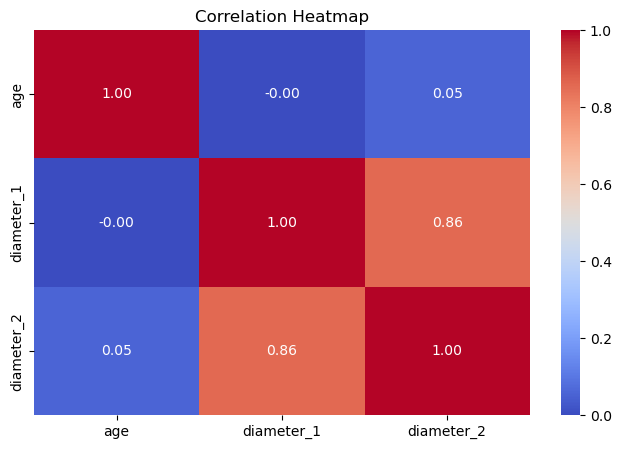

In [81]:
# 62. CORRELATION HEATMAP

plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

### OUTLIER ANALYSIS

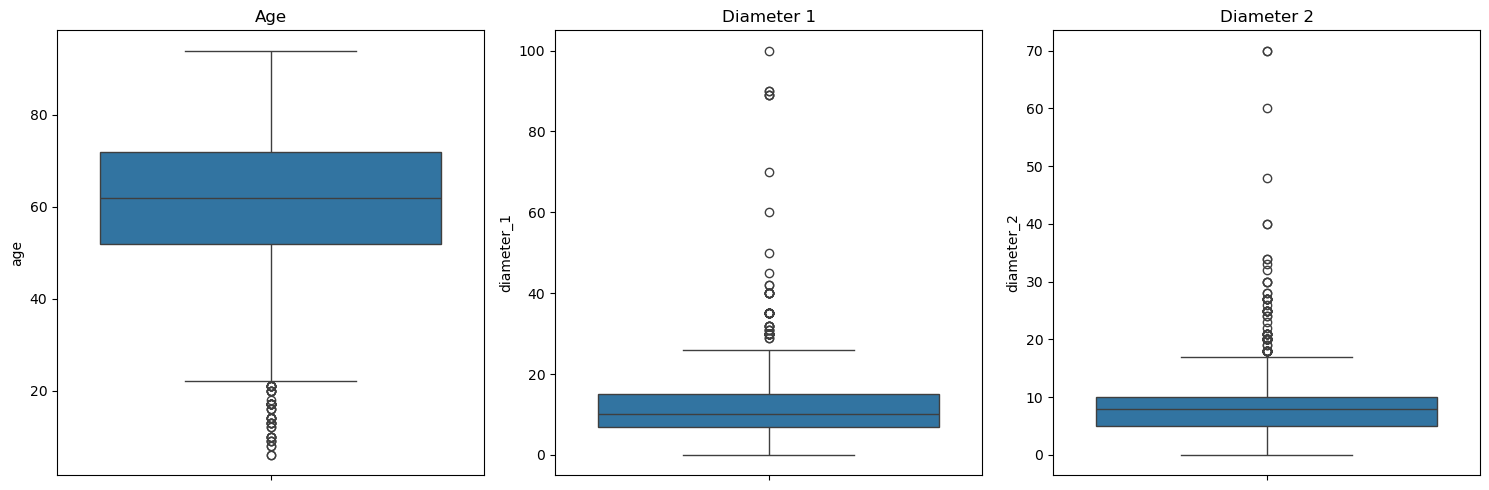

In [82]:
# 63. OUTLIER ANALYSIS

# Create boxplots for numerical variables
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.boxplot(data=df, y="age", ax=axes[0])
axes[0].set_title("Age")

sns.boxplot(data=df, y="diameter_1", ax=axes[1])
axes[1].set_title("Diameter 1")

sns.boxplot(data=df, y="diameter_2", ax=axes[2])
axes[2].set_title("Diameter 2")

plt.tight_layout()
plt.show()

### Calculate quartiles for Age

In [83]:
# 64. Calculate quartiles
Q1 = df["age"].quantile(0.25)
Q3 = df["age"].quantile(0.75)

# Calculate Interquartile Range
IQR = Q3 - Q1

# Calculate outlier boundaries
lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

# Display results
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 52.0
Q3: 72.0
IQR: 20.0
Lower Bound: 22.0
Upper Bound: 102.0


In [84]:
# 65. Identify potential outliers
outliers = df[
    (df["age"] < lower_bound) |
    (df["age"] > upper_bound)
]

print("Number of potential outliers:", len(outliers))

Number of potential outliers: 53


In [85]:
# 66. Display potential age outliers
print(outliers["age"].sort_values().to_list())

[6, 6, 8, 8, 9, 9, 9, 10, 10, 10, 10, 10, 12, 12, 13, 13, 13, 13, 13, 14, 14, 14, 14, 14, 14, 16, 16, 16, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 18, 20, 20, 20, 20, 20, 21, 21, 21, 21, 21, 21, 21, 21]


### Age Outlier Analysis

Using the IQR method, 53 potential outliers were identified in the age variable.

All identified values were below the lower boundary of 22, ranging from 6 to 21 years.

These observations were not removed because they may represent genuine patient records rather than data-entry errors.

### Calculate Quartiles for Diameter 1

In [86]:
# 67. Calculate quartiles
Q1 = df["diameter_1"].quantile(0.25)
Q3 = df["diameter_1"].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Calculate outlier boundaries
lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

# Display results
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 7.0
Q3: 15.0
IQR: 8.0
Lower Bound: -5.0
Upper Bound: 27.0


In [87]:
# 68. Identify potential outliers
outliers_d1 = df[
    (df["diameter_1"] < lower_bound) |
    (df["diameter_1"] > upper_bound)
]

print("Number of potential outliers:", len(outliers_d1))

Number of potential outliers: 63


In [88]:
# 69. Display potential outlier values
print(outliers_d1["diameter_1"].sort_values().to_list())

[29.0, 29.0, 30.0, 30.0, 30.0, 30.0, 30.0, 30.0, 30.0, 30.0, 30.0, 30.0, 30.0, 30.0, 30.0, 30.0, 30.0, 30.0, 30.0, 30.0, 30.0, 31.0, 31.0, 31.0, 32.0, 32.0, 32.0, 32.0, 32.0, 35.0, 35.0, 35.0, 35.0, 35.0, 35.0, 35.0, 35.0, 35.0, 35.0, 35.0, 35.0, 35.0, 35.0, 35.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 42.0, 42.0, 45.0, 50.0, 60.0, 70.0, 89.0, 89.0, 89.0, 90.0, 90.0, 100.0]


### Diameter 1 Outlier Analysis

Using the IQR method, 63 potential outliers were identified in diameter_1.

The upper boundary was 27, and the identified values ranged from 29 to 100.

Most potential outliers were between 29 and 40, with a few considerably larger values.

These observations were retained for further investigation because they may represent genuine measurements rather than data-entry errors.

### Calculate Quartiles for Diameter 2

In [89]:
# 70. Calculate quartiles
Q1 = df["diameter_2"].quantile(0.25)
Q3 = df["diameter_2"].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Calculate outlier boundaries
lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

# Display results
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 5.0
Q3: 10.0
IQR: 5.0
Lower Bound: -2.5
Upper Bound: 17.5


In [90]:
# 71. Identify potential outliers
outliers_d2 = df[
    (df["diameter_2"] < lower_bound) |
    (df["diameter_2"] > upper_bound)
]

print("Number of potential outliers:", len(outliers_d2))

Number of potential outliers: 102


In [91]:
# 72. Display potential outlier values
print(outliers_d2["diameter_2"].sort_values().to_list())

[18.0, 18.0, 18.0, 18.0, 18.0, 18.0, 18.0, 18.0, 18.0, 18.0, 18.0, 18.0, 18.0, 18.0, 18.0, 18.0, 18.0, 18.0, 18.0, 18.0, 18.0, 18.0, 18.0, 19.0, 19.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 21.0, 21.0, 21.0, 21.0, 21.0, 21.0, 21.0, 21.0, 22.0, 23.0, 24.0, 24.0, 25.0, 25.0, 25.0, 25.0, 25.0, 25.0, 25.0, 25.0, 25.0, 26.0, 27.0, 27.0, 27.0, 27.0, 27.0, 27.0, 27.0, 27.0, 28.0, 28.0, 30.0, 30.0, 30.0, 32.0, 33.0, 34.0, 34.0, 40.0, 40.0, 48.0, 60.0, 70.0, 70.0]


### Outlier Analysis

The Interquartile Range (IQR) method was used to identify potential outliers in the numerical variables.

- **Age:** 53 potential outliers were identified, ranging from 6 to 21 years.
- **Diameter 1:** 63 potential outliers were identified, ranging from 29 to 100.
- **Diameter 2:** 102 potential outliers were identified, ranging from 18 to 70.

The diameter variables showed potential outliers on the upper end of their distributions, consistent with their right-skewed distributions.

The identified observations were not removed because they may represent genuine patient measurements. Further investigation is required before deciding whether any values should be modified or excluded.

### Missing Value Patterns

In [93]:
# 73. MISSING VALUE PATTERN ANALYSIS

# Count missing values in each row
missing_per_row = df.isnull().sum(axis=1)

# Count how many rows have each number of missing values
missing_per_row.value_counts().sort_index()

0     1474
1        8
2       12
13     804
Name: count, dtype: int64

In [94]:
# 74. Select rows with exactly 13 missing values
rows_with_13_missing = df[missing_per_row == 13]

# Display columns that contain missing values
rows_with_13_missing.isnull().sum()

patient_id               0
lesion_id                0
smoke                  804
drink                  804
background_father      804
background_mother      804
age                      0
pesticide              804
gender                 804
skin_cancer_history    804
cancer_history         804
has_piped_water        804
has_sewage_system      804
fitspatrick            804
region                   0
diameter_1             804
diameter_2             804
diagnostic               0
itch                     0
grew                     0
hurt                     0
changed                  0
bleed                    0
elevation                0
img_id                   0
biopsed                  0
dtype: int64

### Missing Value Pattern Analysis

The missing-value investigation revealed that 804 records contain exactly 13 missing values.

The missing values occur consistently in the same 13 columns, including demographic information, medical history, skin characteristics and lesion measurements.

The remaining 1,494 records contain complete information in these columns.

This suggests a structured missing-data pattern rather than completely random missing values.

The reason for this pattern requires further investigation before selecting an imputation strategy.

In [95]:
# 75. Compare diagnostic distributions
# between complete and incomplete records

df["missing_group"] = np.where(
    missing_per_row == 0,
    "Complete",
    "Incomplete"
)

pd.crosstab(
    df["missing_group"],
    df["diagnostic"],
    normalize="index"
) * 100

diagnostic,ACK,BCC,MEL,NEV,SCC,SEK
missing_group,,,,,,
Complete,18.521031,57.327001,3.527815,4.884668,13.02578,2.713704
Incomplete,55.461165,0.000000,0.000000,20.873786,0.00000,23.665049


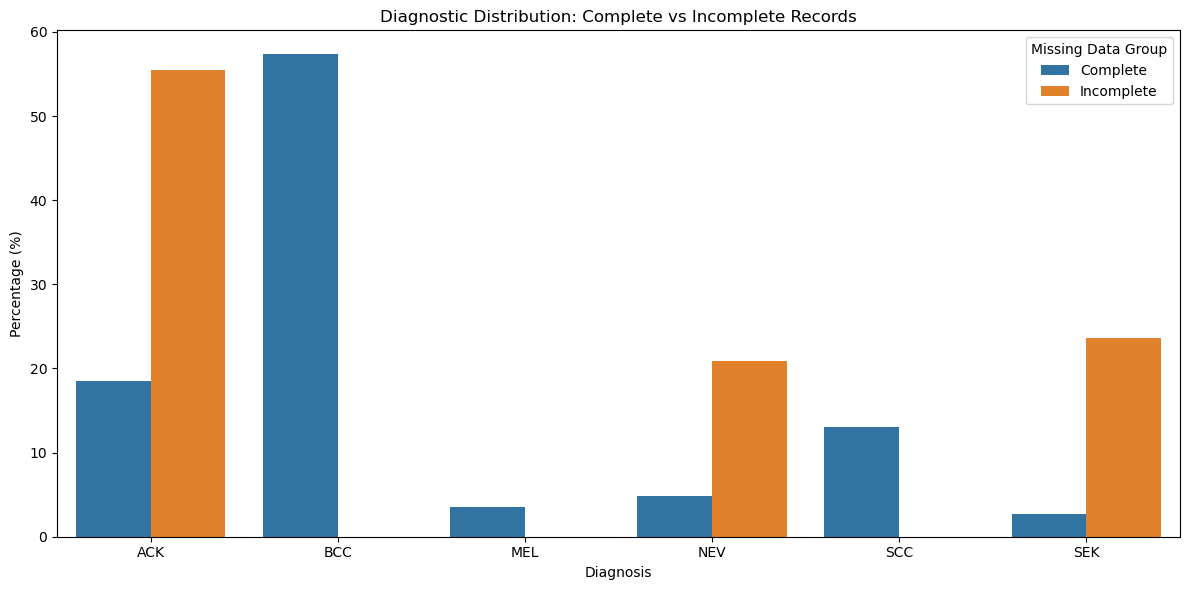

In [96]:
# 76. DIAGNOSTIC DISTRIBUTION BY MISSING GROUP

# Calculate diagnostic percentages
diagnostic_percentages = pd.crosstab(
    df["missing_group"],
    df["diagnostic"],
    normalize="index"
) * 100

# Convert the table into a format suitable for plotting
diagnostic_percentages = diagnostic_percentages.reset_index().melt(
    id_vars="missing_group",
    var_name="diagnostic",
    value_name="percentage"
)

# Create grouped bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    data=diagnostic_percentages,
    x="diagnostic",
    y="percentage",
    hue="missing_group"
)

plt.title("Diagnostic Distribution: Complete vs Incomplete Records")
plt.xlabel("Diagnosis")
plt.ylabel("Percentage (%)")
plt.legend(title="Missing Data Group")
plt.tight_layout()
plt.show()

### Missing Data and Diagnostic Distribution

The diagnostic distribution differs considerably between complete and incomplete records.

Complete records contain all six diagnostic categories, whereas incomplete records contain only ACK, NEV and SEK.

The incomplete group consists of:
- ACK: 55.46%
- NEV: 20.87%
- SEK: 23.67%

BCC, MEL and SCC are absent from the incomplete group.

Removing all incomplete records could therefore introduce selection bias and alter the diagnostic distribution.

Missing-value handling will require careful consideration to preserve the representation of diagnostic classes.

In [97]:
# 77. Compare diagnostic counts
pd.crosstab(
    df["missing_group"],
    df["diagnostic"]
)

diagnostic,ACK,BCC,MEL,NEV,SCC,SEK
missing_group,,,,,,
Complete,273,845,52,72,192,40
Incomplete,457,0,0,172,0,195


### Diagnostic Distribution Across Missing-Data Groups

The diagnostic counts revealed substantial differences between complete and incomplete records.

- All 845 BCC, 52 MEL and 192 SCC records belong to the complete group.
- ACK has 273 complete and 457 incomplete records.
- NEV has 72 complete and 172 incomplete records.
- SEK has 40 complete and 195 incomplete records.

The incomplete group contains 824 records in total, including 804 records with 13 missing values and 20 records with either 1 or 2 missing values.

Removing all incomplete records could substantially alter the diagnostic distribution and introduce selection bias.

In [98]:
# 78. Select records with exactly 13 missing values
group_804 = df[missing_per_row == 13]

# Compare their diagnostic counts
group_804["diagnostic"].value_counts()

diagnostic
ACK    447
SEK    188
NEV    169
Name: count, dtype: int64

### Analysis of Records with 13 Missing Values

The 804 records containing exactly 13 missing values were examined separately.

Their diagnostic distribution was:

- ACK: 447 records (55.60%)
- SEK: 188 records (23.38%)
- NEV: 169 records (21.02%)

BCC, MEL and SCC were absent from this group.

This demonstrates an association between the observed missing-data pattern and the diagnostic category. The reason for this association cannot be established from the distribution alone.

### Duplicate Records

In [99]:
# 79. DUPLICATE ANALYSIS

# Count completely duplicated rows
df.duplicated().sum()

# Count completely duplicated rows
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [100]:
# 80. Count records associated with each patient
df["patient_id"].value_counts()

patient_id
PAT_645     10
PAT_388     10
PAT_330     10
PAT_53       7
PAT_270      7
            ..
PAT_403      1
PAT_1130     1
PAT_841      1
PAT_1020     1
PAT_1714     1
Name: count, Length: 1373, dtype: int64

In [101]:
# 81. Count unique lesion IDs
print("Unique lesions:", df["lesion_id"].nunique())

# Count duplicated lesion IDs
print("Duplicate lesion IDs:", df["lesion_id"].duplicated().sum())

Unique lesions: 1641
Duplicate lesion IDs: 657


In [102]:
# 82. Count occurrences of each lesion ID
lesion_counts = df["lesion_id"].value_counts()

# Display lesion IDs that appear more than once
lesion_counts[lesion_counts > 1]

lesion_id
1246    8
361     6
1402    5
1286    5
1156    4
       ..
3335    2
659     2
738     2
1387    2
824     2
Name: count, Length: 512, dtype: int64

In [103]:
# 83. Inspect records belonging to one repeated lesion
df[df["lesion_id"] == 1246][
    ["patient_id", "lesion_id", "img_id", "diagnostic"]
]

,patient_id,lesion_id,img_id,diagnostic
312,PAT_1364,1246,PAT_1364_1246_420.png,NEV
409,PAT_1364,1246,PAT_1364_1246_927.png,NEV
567,PAT_1364,1246,PAT_1364_1246_447.png,NEV
1091,PAT_1364,1246,PAT_1364_1246_143.png,NEV
1356,PAT_1364,1246,PAT_1364_1246_583.png,NEV
1461,PAT_656,1246,PAT_656_1246_483.png,MEL
1873,PAT_1364,1246,PAT_1364_1246_238.png,NEV
1916,PAT_656,1246,PAT_656_1246_489.png,MEL


In [104]:
# 84. Check duplicates using patient_id and lesion_id together
print(
    "Duplicate patient-lesion combinations:",
    df.duplicated(subset=["patient_id", "lesion_id"]).sum()
)

Duplicate patient-lesion combinations: 407


In [105]:
# 85. Examine one patient-lesion combination
df[
    (df["patient_id"] == "PAT_1364") &
    (df["lesion_id"] == 1246)
][["patient_id", "lesion_id", "img_id", "diagnostic"]]

,patient_id,lesion_id,img_id,diagnostic
312,PAT_1364,1246,PAT_1364_1246_420.png,NEV
409,PAT_1364,1246,PAT_1364_1246_927.png,NEV
567,PAT_1364,1246,PAT_1364_1246_447.png,NEV
1091,PAT_1364,1246,PAT_1364_1246_143.png,NEV
1356,PAT_1364,1246,PAT_1364_1246_583.png,NEV
1873,PAT_1364,1246,PAT_1364_1246_238.png,NEV


In [106]:
# 86. Compare clinical information for the repeated lesion
df[
    (df["patient_id"] == "PAT_1364") &
    (df["lesion_id"] == 1246)
].drop(columns=["img_id"]).T

,312,409,567,1091,1356,1873
patient_id,PAT_1364,PAT_1364,PAT_1364,PAT_1364,PAT_1364,PAT_1364
lesion_id,1246,1246,1246,1246,1246,1246
smoke,NaN,NaN,NaN,NaN,NaN,NaN
drink,NaN,NaN,NaN,NaN,NaN,NaN
background_father,NaN,NaN,NaN,NaN,NaN,NaN
background_mother,NaN,NaN,NaN,NaN,NaN,NaN
age,17,17,17,17,17,17
pesticide,NaN,NaN,NaN,NaN,NaN,NaN
gender,NaN,NaN,NaN,NaN,NaN,NaN
skin_cancer_history,NaN,NaN,NaN,NaN,NaN,NaN


### Repeated Patient-Lesion Records

The dataset contains repeated combinations of patient_id and lesion_id.

An investigation of patient PAT_1364 and lesion 1246 identified six records with identical clinical information but different image identifiers.

This suggests that multiple images may be associated with the same underlying lesion.

Since this project focuses exclusively on tabular data, repeated clinical records may lead to overrepresentation of certain lesions.

Further investigation is required to determine whether these records should be consolidated or retained. Patient-level grouping will also be considered during model evaluation to prevent data leakage.

In [107]:
# 87. Count unique patient-lesion combinations
print(
    "Unique patient-lesion combinations:",
    df[["patient_id", "lesion_id"]].drop_duplicates().shape[0]
)

Unique patient-lesion combinations: 1891


In [108]:
# 88. Count records per patient-lesion combination
combination_counts = df.groupby(
    ["patient_id", "lesion_id"]
).size()

# Count combinations appearing more than once
print(
    "Repeated patient-lesion combinations:",
    (combination_counts > 1).sum()
)

# Show the distribution of occurrences
print(combination_counts.value_counts().sort_index())

Repeated patient-lesion combinations: 361
1    1530
2     324
3      31
4       4
5       1
6       1
Name: count, dtype: int64


### There are 361 patient-lesion combinations that appear more than once.

Let's distinguish two things:
- 361 = number of repeated patient-lesion combinations.
- 407 = number of additional rows caused by those repetitions.
For example, a combination appearing twice contributes one additional row; a combination appearing six times contributes five additional rows.

This explains why we found 407 duplicate patient-lesion combinations at the row level.

In [109]:
# 89. Select clinical columns, excluding identifiers
clinical_columns = df.columns.drop(
    ["patient_id", "lesion_id", "img_id", "missing_group"]
)

# Count distinct values within each patient-lesion combination
clinical_variations = df.groupby(
    ["patient_id", "lesion_id"]
)[clinical_columns].nunique(dropna=False)

# Find combinations with differences in clinical information
inconsistent = clinical_variations[
    (clinical_variations > 1).any(axis=1)
]

print("Inconsistent patient-lesion combinations:", len(inconsistent))

Inconsistent patient-lesion combinations: 0


### Repeated Records and Consistency Analysis

The dataset contains 361 patient-lesion combinations that appear more than once, accounting for 407 additional records.

An investigation of these combinations found no inconsistencies in their clinical information. Repeated records contain identical clinical attributes, although their image identifiers may differ.

This suggests that multiple images are associated with the same patient-lesion combination.

These records are not completely duplicated rows. However, retaining every repeated record could give certain lesions greater representation during model training.

The appropriate treatment of repeated records will be considered during preprocessing.

In [110]:
# 90. Count unique lesions for each patient
lesions_per_patient = df.groupby("patient_id")["lesion_id"].nunique()

# Display summary statistics
lesions_per_patient.describe()

count    1373.000000
mean        1.377276
std         0.764830
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max         8.000000
Name: lesion_id, dtype: float64

# Lesions per Patient

The dataset contains 1,373 unique patients, with an average of approximately 1.38 unique lesions per patient.

The median number of lesions per patient is 1, while the maximum is 8.

This indicates that some patients have multiple lesions recorded in the dataset.

Patient identifiers will therefore be important when splitting the data into training and testing sets, to reduce the risk of data leakage.